# NN_L5_grad_lag

**Sensitivity of the trained day-ahead load forecasts (hour 12 UTC) to each of the 168 input hours: RNN vs LSTM vs GRU, 200 test days.**

Neural Networks and Deep Learning (NN), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L5/NN_L5_grad_lag/NN_L5_grad_lag.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

$S(k)=\frac1n\sum_i|\partial\hat y_{i,12}/\partial x_{i,T+1-k}|$, normalised by its maximum.

rnn: lag 168 relative to the last day maximum = 0.261   [grad.rnn.lag168_rel]
lstm: lag 168 relative to the last day maximum = 0.131   [grad.lstm.lag168_rel]
gru: lag 168 relative to the last day maximum = 0.14   [grad.gru.lag168_rel]


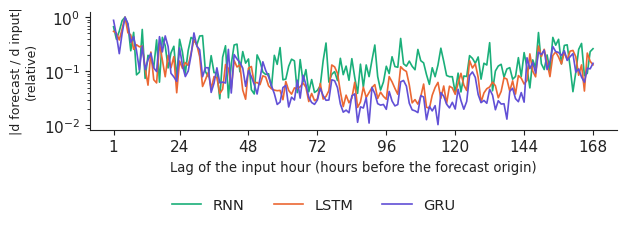

In [3]:
import json, urllib.request
_F = 'grad_lag_results.json'
R = json.load(open(_F)) if os.path.isfile(_F) else json.load(urllib.request.urlopen(REPO + 'Quantlets/L5/NN_L5_grad_lag/' + _F))
for c in ['rnn', 'lstm', 'gru']:
    s = np.array(R[c]); show(f'grad.{c}.lag168_rel', f'{c}: lag 168 relative to the last day maximum', round(float(s[167] / s[:24].max()), 3))
fig, ax = plt.subplots(figsize=(6.4, 2.3))
for c, col in [('rnn', PAL['benchmark']), ('lstm', PAL['model']), ('gru', '#6250d6')]: ax.plot(np.arange(1, 169), R[c], color=col, lw=1.2, label=c.upper())
ax.set_yscale('log'); ax.set_xlabel('Lag of the input hour (hours before the forecast origin)', fontsize=9.5); ax.set_ylabel('|d forecast / d input|\n(relative)', fontsize=9)
ax.set_xticks([1, 24, 48, 72, 96, 120, 144, 168]); legend_bottom(fig, ncol=3); fig.tight_layout(rect=(0, .15, 1, 1))
fig.savefig('grad_lag.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()